# Target engineering

Which value should the model learn? Keep target construction, difference order, and seasonal lag explicit. A reversible transform lets a model learn logs, Box-Cox values, or differences and still return forecasts on the original scale.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp target

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `target`

### Imports and configuration

In [3]:
#| export target
from __future__ import annotations

from typing import TypeVar
from numpy.typing import NDArray

import numpy as np
import pandas as pd

_Pandas = TypeVar("_Pandas", pd.Series, pd.DataFrame)


### Shared positive integer validation

In [4]:
#| export target
from timegym._internal import positive_int


### multioutput_target

In [5]:
#| export target
def multioutput_target(
    df: pd.DataFrame, horizon: int = 10, dropna: bool = True
) -> pd.DataFrame:
    """Append future labels {column}_t+{h} for h=1..horizon, by source column.

    Retain the original columns without mutation; future columns are supervised
    labels and must never enter the predictor matrix. Offsets count rows, not
    calendar durations. dropna=True removes rows missing any value; False keeps
    the index and incomplete tail labels. Existing generated names raise.
    This constructs labels, not a multioutput forecasting adapter.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    horizon = positive_int(horizon, "horizon")
    df = df.copy()
    for col in df.columns:
        for h in range(1, 1 + horizon):
            name = f"{col}_t+{h}"
            if name in df.columns:
                raise ValueError(f"Future target column already exists: {name}")
            df[name] = df[col].shift(-h)
    return df.dropna() if dropna else df


### onestep_target

In [6]:
#| export target
def onestep_target(df: pd.DataFrame, dropna: bool = True) -> pd.DataFrame:
    """Append each next-row label with multioutput_target's copy/missing contract.

    A recursive forecaster can train on these labels; the helper itself does
    not fit a model or feed predictions back into future inputs.
    """
    return multioutput_target(df, horizon=1, dropna=dropna)


### step_ahead_target

In [7]:
#| export target
def step_ahead_target(
    df: pd.DataFrame, step: int = 5, dropna: bool = True
) -> pd.DataFrame:
    """Append only the label step rows ahead for each original column.

    Keep original columns and never mutate the input. dropna=True removes rows
    missing any original or future value; False retains the incomplete tail.
    Generated names must not collide. This supplies labels for a chosen horizon,
    not a direct forecasting adapter.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    step = positive_int(step, "step")
    df = df.copy()
    for col in df.columns:
        name = f"{col}_t+{step}"
        if name in df.columns:
            raise ValueError(f"Future target column already exists: {name}")
        df[name] = df[col].shift(-step)
    return df.dropna() if dropna else df


### fractional_weights — The first lags binomial coefficients of the operator (1-B)^d.

In [8]:
#| export target
def fractional_weights(d: float, lags: int) -> NDArray[np.float64]:
    """Return (lags, 1) binomial coefficients of (1-B)^d, newest first.

    d may be any finite real order; lags includes the current observation's
    coefficient 1. The array is a finite truncation, not an infinite filter.
    """
    lags = positive_int(lags, "lags")
    if isinstance(d, (bool, np.bool_)):
        raise ValueError("d must be finite and real")
    d = float(d)
    if not np.isfinite(d):
        raise ValueError("d must be finite")
    weights = [1.0]
    for k in range(1, lags):
        weights.append(-weights[-1] * (d - k + 1) / k)
    return np.asarray(weights).reshape(-1, 1)


### fractional_differencing — Apply a finite binomial approximation to (1-B^lag)^order.

In [9]:
#| export target
def fractional_differencing(
    series: _Pandas, order: float, fractional_coefficients: int, *, lag: int = 1
) -> _Pandas:
    """Apply a finite binomial approximation to (1-B^lag)^order.

    Discard only the initial (fractional_coefficients-1)*lag rows that do not
    have a full history. Missing observations inside the series propagate.
    Transform all columns independently, retaining pandas type and labels;
    never mutate the input. Order zero returns a copy without trimming.
    Restore the original target scale in the model before forecast evaluation.
    """
    if not isinstance(series, (pd.Series, pd.DataFrame)):
        raise TypeError("series must be a pandas Series or DataFrame")
    if isinstance(order, (bool, np.bool_)):
        raise ValueError("order must be finite and nonnegative")
    count = positive_int(fractional_coefficients, "fractional_coefficients")
    lag = positive_int(lag, "lag")
    order = float(order)
    if not np.isfinite(order) or order < 0:
        raise ValueError("order must be finite and nonnegative")
    if order == 0:
        return series.copy()
    weights = fractional_weights(order, count)[:, 0]
    result = sum(weights[k] * series.shift(k * lag) for k in range(count))
    return result.iloc[(count - 1) * lag :]


### differencing — Apply repeated lag differences; order is not a lag distance.

In [10]:
#| export target
def differencing(
    series: _Pandas,
    order: float = 1,
    fractional_coefficients: int = 10,
    *,
    lag: int = 1
) -> _Pandas:
    """Apply repeated lag differences; order is not a lag distance.

    order=2 means y[t]-2*y[t-lag]+y[t-2*lag]. For a seasonal first difference
    use order=1, lag=period. Order zero returns a copy unchanged. Noninteger
    orders use the explicitly truncated fractional approximation.
    Return the same pandas type and labels, trimming order*lag warmup rows for
    integer orders. Internal missing values propagate. All columns are treated
    independently without mutation. fractional_coefficients is used only for
    noninteger orders; lag counts rows, not calendar durations.
    """
    if not isinstance(series, (pd.Series, pd.DataFrame)):
        raise TypeError("series must be a pandas Series or DataFrame")
    lag = positive_int(lag, "lag")
    if isinstance(order, (bool, np.bool_)):
        raise ValueError("order must be a finite nonnegative number")
    order = float(order)
    if not np.isfinite(order) or order < 0:
        raise ValueError("order must be a finite nonnegative number")
    if order.is_integer():
        result = series.copy()
        for _ in range(int(order)):
            result = result.diff(periods=lag)
        return result.iloc[int(order) * lag :]
    return fractional_differencing(series, order, fractional_coefficients, lag=lag)


### Reversible target transforms

A transform is fitted on one forecast context and keeps the state needed to undo it: the Box-Cox lambdas, or the last observations a difference consumed. `fit_transform(context)` returns what the model learns from; `inverse_transform(forecast)` maps the model's forecast back. Samples and quantiles invert elementwise, and increasing maps keep quantiles in order. Points need more care: the inverse of a transformed-scale mean is not the original-scale mean.

In [11]:
#| export target
import dataclasses
from collections.abc import Sequence

from scipy import optimize, special, stats

from timegym._internal import _real_array
from timegym.contracts import Forecast

### _TargetTransform — Configuration, fitted state, and forecast checks shared by bundled transforms.

In [12]:
#| export target
def _context_values(context: pd.DataFrame) -> NDArray[np.float64]:
    if not isinstance(context, pd.DataFrame):
        raise TypeError("context must be a pandas DataFrame")
    values = _real_array(context.to_numpy(), "context")
    if values.size == 0 or not np.isfinite(values).all():
        raise ValueError("context must contain finite numeric values")
    return values


def _positive_values(context: pd.DataFrame, owner: str) -> NDArray[np.float64]:
    values = _context_values(context)
    nonpositive = values <= 0
    if nonpositive.any():
        column = int(np.argmax(nonpositive.any(axis=0)))
        row = int(np.argmax(nonpositive[:, column]))
        raise ValueError(
            f"{owner} requires strictly positive context values; target {context.columns[column]!r} "
            f"has {int(nonpositive[:, column].sum())} nonpositive value(s), the first at index "
            f"{context.index[row]!r}")
    return values


class _TargetTransform:
    """Configuration, fitted state, and forecast checks shared by bundled transforms."""

    def params(self) -> dict:
        return {}

    def clone_unfitted(self):
        return type(self)(**self.params())

    def _fitted_on(self, context: pd.DataFrame) -> None:
        self.target_names_ = tuple(context.columns)

    def _check_forecast(self, forecast: Forecast) -> Forecast:
        """Return the forecast to invert; unnamed series are the fitted context's."""
        if not hasattr(self, "target_names_"):
            raise ValueError(f"Call {type(self).__name__}.fit_transform(context) before inverse_transform")
        if not isinstance(forecast, Forecast):
            raise TypeError("inverse_transform requires a timegym.Forecast")
        if forecast.target_names is None:
            forecast = dataclasses.replace(forecast, target_names=self.target_names_)
        problems = sorted({problem["code"] for problem in forecast.validate()})
        if problems:
            raise ValueError(f"Cannot invert a forecast that violates its contract: {', '.join(problems)}")
        if tuple(forecast.target_names) != self.target_names_:
            raise ValueError("Forecast targets or their order differ from the fitted context")
        return forecast


def _invert_elementwise(forecast: Forecast, inverse) -> Forecast:
    """Map every output through an increasing inverse ``inverse(values, target_axis)``.

    Samples and quantiles map elementwise, so quantiles stay ordered. The
    inverse of a transformed-scale mean is not the original-scale mean: a
    point becomes the mean of the inverted samples, else the inverted 0.5
    quantile, else the inverted point read as a transformed-scale median.
    """
    levels = tuple(float(level) for level in forecast.levels)
    samples = None if forecast.samples is None else inverse(_real_array(forecast.samples, "samples"), -1)
    quantiles = None if forecast.quantiles is None else inverse(_real_array(forecast.quantiles, "quantiles"), -2)
    point = None
    if forecast.point is not None:
        if samples is not None:
            point = samples.mean(axis=0)
        elif quantiles is not None and 0.5 in levels:
            point = quantiles[..., levels.index(0.5)]
        else:
            point = inverse(_real_array(forecast.point, "point"), -1)
    return Forecast(index=forecast.index.copy(), point=point, quantiles=quantiles, levels=levels,
                    samples=samples, target_names=tuple(forecast.target_names))

### LogTransform — Natural logarithm of a strictly positive target.

In [13]:
#| export target
class LogTransform(_TargetTransform):
    """Natural logarithm of a strictly positive target, inverted by exp.

    Samples and quantiles invert elementwise. exp(mean of logs) is not the
    original-scale mean, so the inverted point is the mean of exp(samples),
    else exp of the 0.5 quantile, else exp of the point read as a median.
    """

    def fit_transform(self, context: pd.DataFrame) -> pd.DataFrame:
        """Record the target names and return the log of a strictly positive context."""
        values = _positive_values(context, "LogTransform")
        self._fitted_on(context)
        return pd.DataFrame(np.log(values), index=context.index.copy(), columns=context.columns.copy())

    def inverse_transform(self, forecast: Forecast) -> Forecast:
        """Return a forecast that meets its contract on the original scale."""
        forecast = self._check_forecast(forecast)
        return _invert_elementwise(forecast, lambda values, axis: np.exp(values))

### BoxCoxTransform — One bounded power per target, estimated on the context only.

In [14]:
#| export target
def _box_cox_lambda(values: NDArray[np.float64]) -> float:
    """Maximize the Box-Cox profile likelihood over [-1, 2], from reciprocal to square."""
    result = optimize.minimize_scalar(lambda power: -stats.boxcox_llf(power, values),
                                      bounds=(-1.0, 2.0), method="bounded")
    return float(result.x)


class BoxCoxTransform(_TargetTransform):
    """Box-Cox transform with one lambda per target, fitted by maximum likelihood on the context.

    The lambdas are recomputed for every context and never see future values.
    Each lies in [-1, 2]: on short contexts the unbounded estimate can be so
    extreme that ordinary forecast noise has no preimage. Inversion follows
    LogTransform's point rule. A transformed value v with lambda * v + 1 <= 0
    has no Box-Cox preimage, and inverting it raises.
    """

    def fit_transform(self, context: pd.DataFrame) -> pd.DataFrame:
        """Fit one lambda per target on this context and return the transformed context."""
        values = _positive_values(context, "BoxCoxTransform")
        constant = np.ptp(values, axis=0) == 0
        if constant.any():
            raise ValueError(f"Box-Cox lambda is not identified for target {context.columns[np.argmax(constant)]!r}, "
                             "which is constant in the context")
        self.lambdas_ = np.array([_box_cox_lambda(column) for column in values.T])
        self._fitted_on(context)
        return pd.DataFrame(special.boxcox(values, self.lambdas_), index=context.index.copy(),
                            columns=context.columns.copy())

    def inverse_transform(self, forecast: Forecast) -> Forecast:
        """Return a forecast that meets its contract on the original scale.

        Raises when a value has no Box-Cox preimage.
        """
        forecast = self._check_forecast(forecast)
        return _invert_elementwise(forecast, self._inverse)

    def _inverse(self, values: NDArray[np.float64], axis: int) -> NDArray[np.float64]:
        lambdas = self.lambdas_.reshape((-1,) + (1,) * (-axis - 1))
        outside = (lambdas != 0) & (lambdas * values + 1 <= 0)
        if outside.any():
            raise ValueError(f"Box-Cox inverse is undefined for {int(outside.sum())} forecast value(s) "
                             "with lambda * value + 1 <= 0")
        return special.inv_boxcox(values, lambdas)

### DifferenceTransform — Integer or seasonal differences with the history needed to undo them.

In [15]:
#| export target
class DifferenceTransform(_TargetTransform):
    """Repeated lag differences that keep the context tail needed to undo them.

    ``order`` counts repeated differences and ``lag`` is their distance, as in
    ``differencing``: order=1, lag=12 is a monthly seasonal difference. The
    forecast rows must be the steps that immediately follow the context.
    Points (means) and samples integrate exactly. Marginal quantiles of
    differences do not determine quantiles of their sums, so quantiles are
    recomputed from the integrated samples, or omitted without samples.
    """

    def __init__(self, order=1, lag=1):
        self.order = positive_int(order, "order")
        self.lag = positive_int(lag, "lag")

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return {"order": self.order, "lag": self.lag}

    def fit_transform(self, context: pd.DataFrame) -> pd.DataFrame:
        """Keep the context tail needed for inversion and return the differenced context."""
        _context_values(context)
        span = self.order * self.lag
        if len(context) <= span:
            raise ValueError(f"DifferenceTransform(order={self.order}, lag={self.lag}) needs more than "
                             f"{span} context rows")
        self.tails_ = [differencing(context, stage, lag=self.lag).to_numpy(dtype=float)[-self.lag:]
                       for stage in range(self.order)]
        self._fitted_on(context)
        return differencing(context, self.order, lag=self.lag)

    def inverse_transform(self, forecast: Forecast) -> Forecast:
        """Integrate a forecast that meets its contract back to levels.

        Quantiles are recomputed from the integrated samples, or omitted
        without samples.
        """
        forecast = self._check_forecast(forecast)
        point = None if forecast.point is None else self._integrate(_real_array(forecast.point, "point"))
        samples = None if forecast.samples is None else self._integrate(_real_array(forecast.samples, "samples"))
        quantiles, levels = None, ()
        if forecast.quantiles is not None:
            if samples is not None:
                levels = tuple(float(level) for level in forecast.levels)
                quantiles = np.moveaxis(np.quantile(samples, levels, axis=0), 0, -1)
            elif point is None:
                raise ValueError("Quantiles of differences do not determine quantiles of levels; "
                                 "DifferenceTransform needs a point or samples to invert")
        return Forecast(index=forecast.index.copy(), point=point, quantiles=quantiles, levels=levels,
                        samples=samples, target_names=self.target_names_)

    def _integrate(self, values: NDArray[np.float64]) -> NDArray[np.float64]:
        for tail in reversed(self.tails_):
            restored = np.concatenate([np.broadcast_to(tail, values.shape[:-2] + tail.shape), values], axis=-2)
            for step in range(values.shape[-2]):
                restored[..., self.lag + step, :] += restored[..., step, :]
            values = restored[..., self.lag:, :]
        return values

### ComposedTransform — Apply bundled transforms in order and invert them in reverse.

In [16]:
#| export target
class ComposedTransform(_TargetTransform):
    """Apply bundled transforms in order and invert them in reverse order.

    Members are LogTransform, BoxCoxTransform or DifferenceTransform
    instances, copied unfitted so that no instance holds two fitted states.
    """

    def __init__(self, transforms):
        if isinstance(transforms, (str, bytes)) or not isinstance(transforms, Sequence) or not transforms:
            raise ValueError("transforms must be a nonempty sequence of bundled target transforms")
        for transform in transforms:
            if type(transform) not in (LogTransform, BoxCoxTransform, DifferenceTransform):
                raise TypeError("ComposedTransform members must be LogTransform, BoxCoxTransform or "
                                f"DifferenceTransform instances, not {type(transform).__name__}")
        self.transforms = tuple(transform.clone_unfitted() for transform in transforms)

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return {"transforms": self.transforms}

    def fit_transform(self, context: pd.DataFrame) -> pd.DataFrame:
        """Fit and apply each member in order, each on the previous member's output."""
        _context_values(context)
        self._fitted_on(context)
        for transform in self.transforms:
            context = transform.fit_transform(context)
        return context

    def inverse_transform(self, forecast: Forecast) -> Forecast:
        """Invert the members in reverse order."""
        forecast = self._check_forecast(forecast)
        for transform in reversed(self.transforms):
            forecast = transform.inverse_transform(forecast)
        return forecast

### transform_config, transform_from_config — Describe and rebuild bundled transforms without imports.

In [17]:
#| export target
_BUNDLED_TRANSFORMS = {kind.__name__: kind for kind in
                       (LogTransform, BoxCoxTransform, DifferenceTransform, ComposedTransform)}


def transform_config(transform) -> dict:
    """Describe a target transform for pipeline configuration and replay.

    Only exact bundled classes are described as ``builtin``; any other object,
    including a subclass, is ``external`` and cannot be rebuilt from data.
    """
    kind = type(transform)
    if _BUNDLED_TRANSFORMS.get(kind.__name__) is not kind:
        return {"kind": "external", "module": kind.__module__, "qualname": kind.__qualname__,
                "reason": "Only bundled target transforms are rebuilt from configuration data."}
    parameters = transform.params()
    if kind is ComposedTransform:
        parameters = {"transforms": [transform_config(member) for member in parameters["transforms"]]}
    return {"kind": "builtin", "class": kind.__name__, "parameters": parameters}


def transform_from_config(config: dict) -> _TargetTransform:
    """Rebuild an unfitted bundled transform from ``transform_config`` output."""
    if not isinstance(config, dict) or set(config) != {"kind", "class", "parameters"} or config["kind"] != "builtin":
        raise ValueError("Replay accepts only bundled target transform descriptions")
    name, parameters = config["class"], config["parameters"]
    if not isinstance(name, str) or name not in _BUNDLED_TRANSFORMS:
        raise ValueError("Target transform class is not in the replay allowlist")
    if name == "ComposedTransform":
        if (not isinstance(parameters, dict) or set(parameters) != {"transforms"}
                or not isinstance(parameters["transforms"], list)):
            raise ValueError("Unexpected or missing target transform parameters")
        members = [transform_from_config(member) for member in parameters["transforms"]]
        if any(isinstance(member, ComposedTransform) for member in members):
            raise ValueError("A composed target transform cannot contain another composition")
        return ComposedTransform(members)
    if not isinstance(parameters, dict) or set(parameters) != set(_BUNDLED_TRANSFORMS[name]().params()):
        raise ValueError("Unexpected or missing target transform parameters")
    return _BUNDLED_TRANSFORMS[name](**parameters)

## A first difference is not a seasonal difference

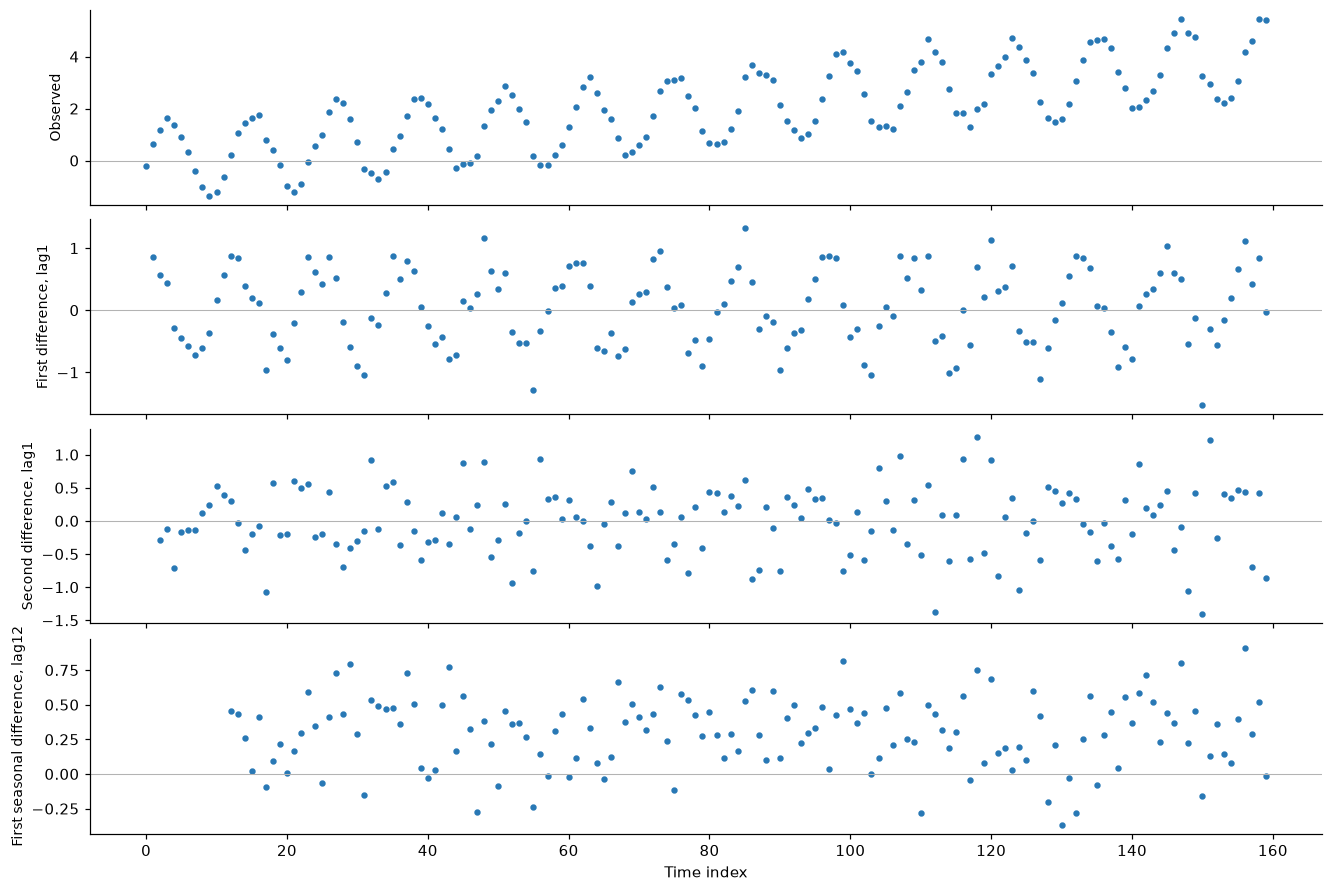

In [18]:
time = np.arange(160)
rng = np.random.default_rng(10)
series = pd.Series(.025 * time + 1.5 * np.sin(2 * np.pi * time / 12) + rng.normal(0, .2, len(time)), name='y')
transforms = {'Observed': series, 'First difference, lag1': differencing(series, order=1),
              'Second difference, lag1': differencing(series, order=2),
              'First seasonal difference, lag12': differencing(series, order=1, lag=12)}
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True, layout='constrained')
for ax, (label, transformed) in zip(axes, transforms.items()):
    ax.scatter(transformed.index, transformed, s=10, color='#2878b5')
    ax.axhline(0, color='.7', lw=.7)
    ax.set_ylabel(label, fontsize=9)
axes[-1].set_xlabel('Time index')
plt.show()
pd.testing.assert_series_equal(differencing(series, order=2), series.diff().diff().iloc[2:])

Order2 applies two successive differences; lag12 compares the same season. Differencing changes the target and its scale. A forecasting model must restore the original scale before evaluation; `DifferenceTransform` below keeps the history that restoration needs.

## Inspect the supervised targets

In [19]:
small = pd.DataFrame({'y': np.arange(8, dtype=float)})
display(multioutput_target(small, horizon=3))
assert len(multioutput_target(small, horizon=3)) == 5

,y,y_t+1,y_t+2,y_t+3
0,0.0,1.0,2.0,3.0
1,1.0,2.0,3.0,4.0
2,2.0,3.0,4.0,5.0
3,3.0,4.0,5.0,6.0
4,4.0,5.0,6.0,7.0


Each future column is a label, never an input available at the origin. This helper constructs supervised targets; the direct and multioutput reductions of chapter 06 build their own labels from lag windows.

## Undo a seasonal difference

Fit the transform on the first 136 observations only. Passing the true future differences back through the inverse must reproduce the held-out values exactly. A Gaussian AR(1) then learns the differences, and its forecast returns to the original scale.

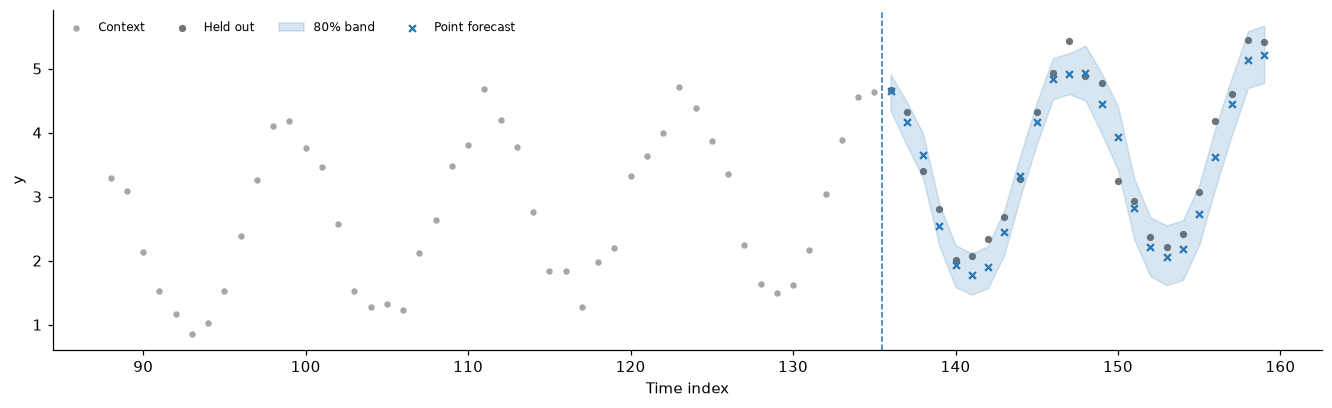

In [20]:
from timegym import Forecast, GaussianAR1Forecaster

context, future = series.iloc[:136].to_frame(), series.iloc[136:].to_frame()
seasonal = DifferenceTransform(lag=12)
differenced = seasonal.fit_transform(context)
true_differences = differencing(series.to_frame(), lag=12).iloc[-len(future):]
exact = seasonal.inverse_transform(Forecast(index=future.index, point=true_differences.to_numpy()))
np.testing.assert_allclose(exact.point, future.to_numpy())

model = GaussianAR1Forecaster(n_samples=500, seed=1).fit(differenced)
restored = seasonal.inverse_transform(model.predict(future.index))
assert restored.validate() == []
fig, ax = plt.subplots(figsize=(12, 3.6), layout='constrained')
ax.scatter(context.index[-48:], context['y'].iloc[-48:], s=10, color='.65', label='Context')
ax.scatter(future.index, future['y'], s=14, color='.45', label='Held out')
ax.fill_between(future.index, restored.quantiles[:, 0, 0], restored.quantiles[:, 0, -1],
                color='#2878b5', alpha=.18, label='80% band')
ax.scatter(future.index, restored.point[:, 0], marker='x', s=20, color='#2878b5', label='Point forecast')
ax.axvline(context.index[-1] + .5, color='#2878b5', ls='--', lw=1)
ax.set(xlabel='Time index', ylabel='y')
ax.legend(fontsize=8, ncol=4)
plt.show()

Each forecast step adds the observation one season earlier, observed or already reconstructed. Points and sample paths integrate exactly. The band comes from the integrated sample paths: quantiles of differences do not add up to quantiles of levels.

## A log-scale mean is not an original-scale mean

Exponentiate the series to make it strictly positive with a multiplicative season, fit the AR(1) to its logarithm, and compare three candidate points on the original scale.

In [21]:
positive = np.exp(series / 2).to_frame()
log_context, log_future = positive.iloc[:136], positive.iloc[136:]
log = LogTransform()
log_forecast = GaussianAR1Forecaster(n_samples=4000, seed=2).fit(log.fit_transform(log_context)).predict(log_future.index)
back = log.inverse_transform(log_forecast)
np.testing.assert_allclose(back.quantiles, np.exp(log_forecast.quantiles))
assert np.all(np.diff(back.quantiles, axis=-1) > 0)
np.testing.assert_allclose(back.point, np.exp(log_forecast.samples).mean(axis=0))
display(pd.DataFrame({'exp(log-scale mean)': np.exp(log_forecast.point[:, 0]),
                      'exp(log-scale median)': np.exp(log_forecast.quantiles[:, 0, 1]),
                      'mean of exp(samples)': back.point[:, 0]},
                     index=pd.Index(log_future.index + 1 - log_future.index[0], name='horizon')).iloc[[0, 11, 23]].round(3))
box_cox = BoxCoxTransform()
box_cox.fit_transform(log_context)
print(f'Box-Cox lambda fitted on the context: {box_cox.lambdas_[0]:.3f}')

,exp(log-scale mean),exp(log-scale median),mean of exp(samples)
horizon,,,
1,9.163,9.159,9.545
12,4.562,4.561,5.824
24,3.399,3.369,4.462


Box-Cox lambda fitted on the context: -0.049


Quantiles map through `exp` and keep their order. The mean does not: `exp` is convex, so the mean of the exponentiated samples exceeds the exponential of their log-scale mean, and the gap grows with the log-scale variance. For a Gaussian log-scale law, `exp(mean)` is the original-scale median. The inverted point is therefore the mean of the inverted samples; without samples it is the inverted median. Box-Cox estimates its power from the context alone; a value near zero is close to the log.

## Change one thing

Try one parameter or implementation change, rerun the relevant example, and inspect the figure or assertion. Save before exporting. The package tests provide broader regression coverage; the experiment here is intentionally small.